id: notebooks/00_general.ipynb

project overview: describes the project as a whole, with the goal of realising a VLB interferometer with an 11.5 km baseline

<!-- notebooks/00_general.ipynb -- project overview (Interferosim 0.3.1) -->
# 00 – Interferosim: project overview

---
  DI Erich Schubert, 07925151
  


**Interferosim** is an open-source simulator for radio interferometry with interactive notebooks for teaching (a project of the University of Vienna, OSSDA). Its practical goal is the realisation of a **very-long-baseline interferometer (VLBI) with an 11.5 km baseline** between two independent stations – Wilhelmsburg and Michelbach (Lower Austria) – at the HI line (1420 MHz) and the OH lines (1612–1720 MHz).

The simulator models every step of this instrument *before* it is built: the sky, the antennas and receivers, the signals the SDRs record, the correlation, the image. Each step is a package of the Python library and a notebook in this folder.

This notebook explains
1. what an interferometer measures and why a long baseline,
2. what makes the system a *VLB* interferometer (independent stations, recorded data, offline correlation),
3. the key figures of the 11.5 km baseline: resolution, delay, fringe rate, data rate,
4. the requirements on clocks and timing,
5. the expected sensitivity,
6. the road map of the project and the notebooks.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import interferosim
from interferosim.constants import C_LIGHT, HI_21CM, OH_1665, OMEGA_SIDEREAL, LINES
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.plotting import plot_array
from interferosim.sky import SkyModel

CFG = Path("..") / "configs"
print("interferosim", interferosim.__version__)

interferosim 0.3.1


## 1. Goal and principle

A single antenna of diameter $D$ resolves angles of about $\lambda/D$. At 21 cm a 3 m dish has a beam of almost 5° – ten times the diameter of the Sun. To resolve finer detail the aperture would have to grow to kilometres.

An **interferometer** replaces the large aperture by two (or more) small antennas a distance $b$ apart. It does not measure an image but one **Fourier component** of the sky brightness, the *visibility* $V(u,v)$ at the spatial frequency $u = b/\lambda$ (van Cittert–Zernike theorem). Its angular resolution is

$$\theta \approx \frac{\lambda}{b}.$$

The Earth's rotation turns the projected baseline during the day, so one baseline samples many $(u,v)$ points (*Earth rotation synthesis*); from them an image is reconstructed and deconvolved (CLEAN). Theory: documentation, part *Theory*; notebooks A (fringes) and B (Fourier transformation and correlation).

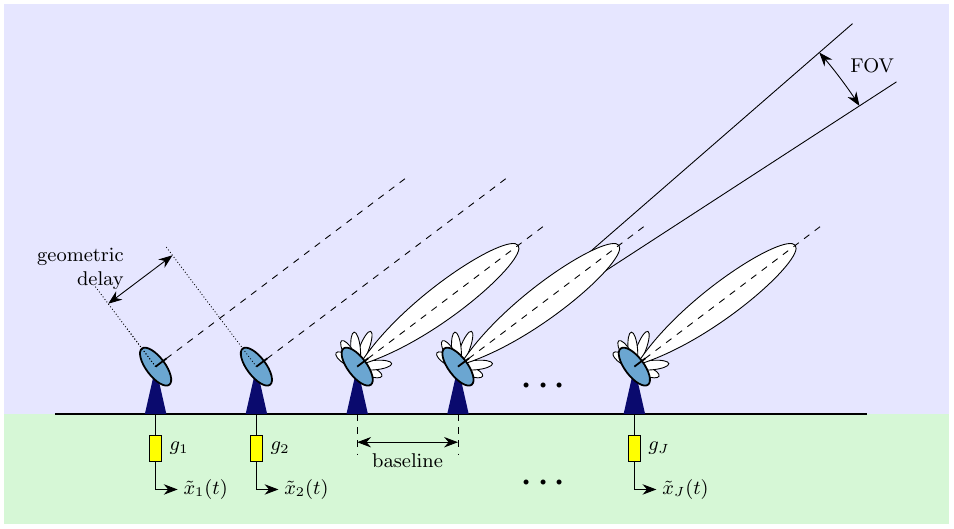

*Array of $J$ antennas pointing at the same source.* The wavefront from the source reaches the antennas at different times; the difference between two antennas is the **geometric delay** – the projection of their **baseline** onto the source direction, divided by $c$. Each antenna sees the sky through its primary beam (main lobe and side lobes); the **field of view** (FOV) is set by the width of the main lobe. Every receiver chain has its own complex gain $g_k$ and delivers the signal $\tilde{x}_k(t)$ – for this project the IQ samples of one B210 per station. The correlator multiplies the signals of each pair of antennas after removing the geometric delay; the averaged product is the visibility of that baseline. Figure: `docs/images/array_geometry.tex` (TikZ).

In [2]:
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
B_TARGET = 11_500.0                                   # m, project baseline
print(f"{'line':<7s} {'lambda [cm]':>11s} {'dish HPBW':>10s} {'lambda/b (11.5 km)':>19s} {'gain in resolution':>19s}")
for name in ("HI", "OH1665"):
    f = LINES[name]; lam = C_LIGHT / f
    hpbw = dish.hpbw_deg(f)                            # degrees
    theta = np.degrees(lam / B_TARGET) * 3600          # arcsec
    print(f"{name:<7s} {lam * 100:11.2f} {hpbw:9.2f}° {theta:17.2f}\" {hpbw * 3600 / theta:18,.0f}x")

line    lambda [cm]  dish HPBW  lambda/b (11.5 km)  gain in resolution
HI            21.11      4.84°              3.79"              4,600x
OH1665        18.00      4.13°              3.23"              4,600x


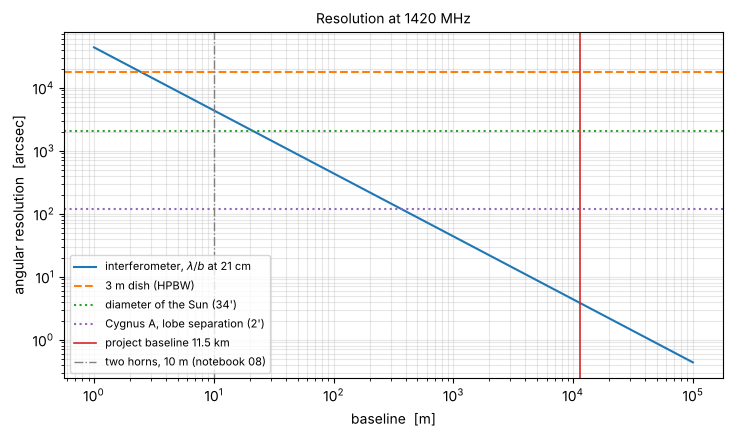

In [3]:
# angular resolution lambda/b over the baseline length, with familiar scales
lam = C_LIGHT / HI_21CM
b = np.logspace(0, 5, 400)
theta_as = np.degrees(lam / b) * 3600
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.loglog(b, theta_as, label=r"interferometer, $\lambda/b$ at 21 cm")
ax.axhline(dish.hpbw_deg() * 3600, color="C1", ls="--", label="3 m dish (HPBW)")
ax.axhline(34 * 60, color="C2", ls=":", label="diameter of the Sun (34')")
ax.axhline(120, color="C4", ls=":", label="Cygnus A, lobe separation (2')")
ax.axvline(B_TARGET, color="C3", lw=1.2, label="project baseline 11.5 km")
ax.axvline(10, color="grey", lw=1, ls="-.", label="two horns, 10 m (notebook 08)")
ax.set_xlabel("baseline  [m]"); ax.set_ylabel("angular resolution  [arcsec]")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Resolution at 1420 MHz", fontsize=10)
plt.show()

## 2. What makes it a *VLB* interferometer

In a connected interferometer both antennas feed one receiver with a common local oscillator, and the signals are correlated in real time. Over 11.5 km a cable is not practical. The project therefore follows the **VLBI principle**:

| Step | Connected interferometer | VLB interferometer (this project) |
|---|---|---|
| Reception | common receiver, common LO | one Ettus USRP B210 per station, own LO |
| Frequency reference | shared | per station: GPS-disciplined oscillator (GPSDO) |
| Time reference | shared clock | GPS time (PPS) at both stations |
| Signal transport | cable | IQ samples **recorded** to disk with time stamps |
| Correlation | in real time | **offline**: delay correction, fringe stopping, residual delay/rate search, cross spectra |
| Result | visibilities | visibilities (same data class `VisData`) |

AAS6 already contains this chain as a simulation (two stations, SDR samples, `geometry.py`, `correlate.py`); Interferosim takes it over in the packages `signal` and `observation` (notebooks 03–05). The simulation is the test bench: every effect – geometric delay, clock offset, oscillator drift, noise – can be switched on and off before real data exist.

## 3. The baseline

The project baseline Wilhelmsburg–Michelbach is 11.5 km (`configs/sites/baseline_wilhelmsburg_michelbach.toml`); notebook A of the teaching material treats it as an east–west baseline. The exact position of the Michelbach station is not yet in the configuration; the closed simulation of AAS6 uses two stations 11.1 km east–west (`aas6_sim_stations.toml`). Here the target baseline is modelled as a station 11.5 km east of Wilhelmsburg.

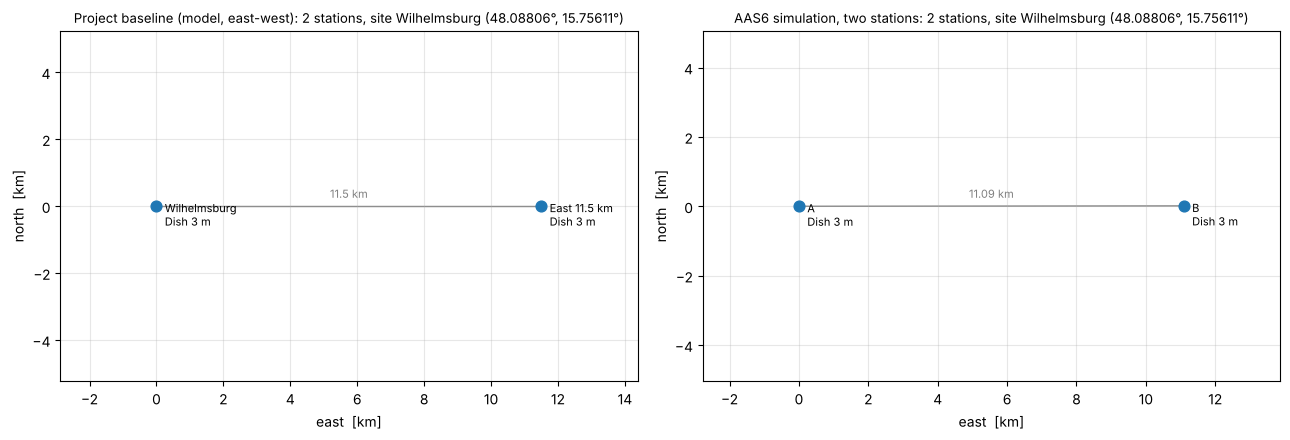

In [4]:
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
target = Array(site, [Station.from_enu("Wilhelmsburg", site, 0.0, 0.0, 0.0, dish),
                      Station.from_enu("East 11.5 km", site, B_TARGET, 0.0, 0.0, dish)],
               receiver=b210, name="Project baseline (model, east-west)")
aas6 = Array.from_toml(CFG / "sites" / "aas6_sim_stations.toml")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_array(target, ax=axes[0]); plot_array(aas6, ax=axes[1])
fig.tight_layout(); plt.show()

### Key figures of the 11.5 km baseline

* **Maximum geometric delay** $\tau_\mathrm{max} = b/c$: the wavefront reaches the stations up to 38 µs apart. The correlator must shift one stream by this delay, to a fraction of a sample.
* **Fringe rate**: the Earth's rotation changes $\tau_g$ continuously; the phase $2\pi f\tau_g$ turns at up to $\omega_E\,b/\lambda$ – several turns per second, which the correlator removes (*fringe stopping*).
* **Delay rate** $\omega_E b/c$ and the **coherence bandwidth**: a residual delay error $\delta\tau$ turns the phase across the band by $2\pi B\,\delta\tau$, so the delay must be known to much better than $1/B$.
* **Data rate**: complex samples of the B210, two numbers per sample.

In [5]:
fs = b210.sample_rate_sps
bw = b210.bandwidth_hz
tau_max = B_TARGET / C_LIGHT
print(f"maximum geometric delay   b/c        = {tau_max * 1e6:8.2f} µs = {tau_max * fs:6.1f} samples at {fs / 1e6:g} MS/s")
print(f"maximum delay rate        w_E b/c    = {OMEGA_SIDEREAL * tau_max:8.2e} s/s")
for name in ("HI", "OH1665"):
    f = LINES[name]
    print(f"maximum fringe rate ({name:6s}) w_E b/lam = {OMEGA_SIDEREAL * B_TARGET * f / C_LIGHT:8.2f} Hz")
print(f"delay accuracy for < 1 rad across {bw / 1e6:g} MHz: |dtau| < 1/(2 pi B) = {1e9 / (2 * np.pi * bw):6.0f} ns")
for fmt, bytes_per_sample in (("sc16 (2 x 16 bit)", 4), ("sc8 (2 x 8 bit)", 2)):
    rate = fs * bytes_per_sample
    print(f"data rate per station, {fmt:18s}: {rate / 1e6:5.1f} MB/s = {rate * 3600 / 1e9:6.1f} GB/h")

maximum geometric delay   b/c        =    38.36 µs =   76.7 samples at 2 MS/s
maximum delay rate        w_E b/c    = 2.80e-09 s/s
maximum fringe rate (HI    ) w_E b/lam =     3.97 Hz
maximum fringe rate (OH1665) w_E b/lam =     4.66 Hz
delay accuracy for < 1 rad across 2 MHz: |dtau| < 1/(2 pi B) =     80 ns
data rate per station, sc16 (2 x 16 bit) :   8.0 MB/s =   28.8 GB/h
data rate per station, sc8 (2 x 8 bit)   :   4.0 MB/s =   14.4 GB/h


## 4. Clocks and timing

With independent stations every error of the frequency reference appears as a phase drift of the fringe: a relative frequency error $y$ shifts the LO by $\Delta f = y\,f$, and the phase turns by one radian in $t_1 = 1/(2\pi\,y f)$. Coherent integration is only possible over times shorter than that – longer integration must be split and averaged incoherently, or the drift must be solved by a fringe-rate search.

Values of the B210 data sheet: internal TCXO ±2 ppm, GPS-locked < 1 ppb (absolute accuracy). The short-term stability of a good disciplined OCXO or rubidium standard is of the order $10^{-11}$–$10^{-12}$ (typical values, to be checked for the chosen device). The GPS PPS of a locked GPSDO is within about 50 ns of GPS time – of the same order as the delay accuracy required for 2 MHz above, so a residual delay search in the correlator remains necessary.

In [6]:
print(f"{'frequency reference':<38s} {'y':>8s} {'LO offset at 1420 MHz':>22s} {'t(1 rad)':>12s}")
for label, y in (("B210 internal TCXO (data sheet)", 2e-6),
                 ("B210 GPS-locked (data sheet, absolute)", 1e-9),
                 ("disciplined OCXO, short term (typical)", 1e-11),
                 ("rubidium / H-maser class (typical)", 1e-12)):
    df = y * HI_21CM
    t1 = 1 / (2 * np.pi * df)
    t_txt = f"{t1 * 1e3:9.2f} ms" if t1 < 1 else f"{t1:9.1f} s"
    print(f"{label:<38s} {y:8.0e} {df:19.3g} Hz {t_txt:>12s}")

frequency reference                           y  LO offset at 1420 MHz     t(1 rad)
B210 internal TCXO (data sheet)           2e-06            2.84e+03 Hz      0.06 ms
B210 GPS-locked (data sheet, absolute)    1e-09                1.42 Hz    112.05 ms
disciplined OCXO, short term (typical)    1e-11              0.0142 Hz       11.2 s
rubidium / H-maser class (typical)        1e-12             0.00142 Hz      112.0 s


Consequence for the design: a free-running TCXO is unusable (kHz offset); a GPSDO at each station is the minimum, and the correlator must search delay **and** fringe rate (AAS6 `correlate.delay_rate_search`). How long one can integrate coherently with the chosen references is one of the questions the simulation (packages `signal`, `observation`) is built to answer.

## 5. Sensitivity

Two 3 m dishes with the B210 ($T_\mathrm{sys} = 120$ K, 2 MHz): noise of one visibility and the expected signal-to-noise ratio for the sky models of notebook 01 at transit on the 11.5 km east–west baseline. Most sources are resolved on this baseline (notebook 02, *choice of the baseline length*); compact structure such as the hotspots of Cygnus A remains.

In [7]:
lam = C_LIGHT / HI_21CM
u = B_TARGET / lam
print(f"u = b/lambda = {u:,.0f} wavelengths")
for t in (10, 60, 600, 3600):
    print(f"  sigma_V({t:5d} s) = {b210.baseline_sigma_jy(dish, dish, t):7.2f} Jy")
print(f"\n{'source':<10s} {'S [Jy]':>9s} {'|V| at 11.5 km [Jy]':>20s} {'S/N 10 min':>11s}")
for n in ("cas_a", "cyg_a", "tau_a", "vir_a", "orion_a", "sun_21cm"):
    s = SkyModel.from_json(CFG / "skies" / f"{n}.json")
    V = abs(s.visibility(u, 0.0))
    print(f"{n:<10s} {s.total_flux_jy:9.0f} {V:20.2f} {V / b210.baseline_sigma_jy(dish, dish, 600):11.1f}")

u = b/lambda = 54,487 wavelengths
  sigma_V(   10 s) =   12.35 Jy
  sigma_V(   60 s) =    5.04 Jy
  sigma_V(  600 s) =    1.59 Jy
  sigma_V( 3600 s) =    0.65 Jy

source        S [Jy]  |V| at 11.5 km [Jy]  S/N 10 min
cas_a           1636                 0.02         0.0
cyg_a           1556                18.69        11.7
tau_a            806                 0.00         0.0
vir_a            210                 4.97         3.1
orion_a          400                 0.00         0.0
sun_21cm      476200                12.74         8.0


The numbers show the central challenge of the project: on 11.5 km the strong sources are largely resolved, and the remaining compact flux needs long integration – which requires stable clocks (section 4). Shorter test baselines (notebook 02) and the Sun with two horns (notebook 08) are the steps towards it.

## 6. Road map

| Version | Package | Content | Notebooks |
|---|---|---|---|
| 0.2 | `sky` | sky models, known regions, maps, visibilities | 01 |
| 0.3 | `instrument` | antennas, B210, sites, stations, arrays, sensitivity | 02 |
| 0.4 | `observation`, `visdata` | source direction, delay, fringe rate, uv-tracks, transit | 04, A |
| 0.5 | `sky` (spectra) | continuum and line spectra (HI, OH) | 09 |
| 0.6 | `signal` | IQ simulation of both stations incl. clock errors, FX correlator | 03, 05, B, C |
| 0.7 | `imaging`, `deconvolution` | gridding, weighting, dirty image, CLEAN, Wiener | 06, 07 |
| later | `io`, `widgets` | FITS, real B210 recordings, correlation of measured data | 08 |

Status of the notebooks: `notebooks/README.md`. Documentation: LaTeX (`docs/`, chapter *Project Description*) and Sphinx (`docs/sphinx/`).

## 7. Working with the notebooks

* Start: `jupyter lab notebooks`, kernel *Python (interferosim)* (project environment `.venv`, see README).
* Every notebook loads its parameters from `configs/` – change a TOML or JSON file, re-run, compare.
* The last section of each notebook is an interactive **selector** (ipywidgets); it needs a running kernel. Static figures above it show the results also on GitHub.
* Units: SI, flux densities in Jy, angles in degrees unless stated; positions WGS84.